# Bloque D2 — Grafo vial dirigido de Bogotá

Trabajo de grado · Ciencia de Datos · Universidad Externado de Colombia

Construye el grafo vial dirigido de las 19 localidades de Bogotá (sin Sumapaz) a
partir de la Malla Vial de Catastro (Mapa de Referencia, capa 13, versión 2024),
y lo exporta para el frente de pendiente.

**Este cuaderno NO calcula pendiente.** Por decisión de la tutoría, la pendiente
la calcula el módulo de terreno con el MDT 2020, y vuelve unida por
`segmento_id` en el cuaderno D3. El cálculo anterior con el MDT 2025 se conserva
en `D2_HISTORICO_pendiente_mdt2025.ipynb` y no forma parte de la producción.

## Qué garantiza este cuaderno

**Datos congelados.** La malla y las localidades se descargaron una sola vez
(corte **2026-09-19**) y se leen de disco: 139 páginas, 138.839 ejes, cada
página con su hash y un manifiesto con el hash del conjunto. El servicio de
Catastro se actualiza trimestralmente y no guarda versiones anteriores, así que
los resultados solo se reproducen con esa carpeta de crudos.

**Identificador estable.** `segmento_id = <MVICODIGO>_<parte>_<FT|TF>`. No
depende de la rejilla de nodos: se comprueba reconstruyendo el grafo con
tolerancia de 2 m y de 3 m, y los identificadores son idénticos.

**Verificación independiente.** Antes de exportar, 10 pruebas recalculan por un
camino distinto lo que se entrega. Si una falla, no se escribe nada.

**Huella de contenido.** Los segmentos se verifican por una huella de
identificador y geometría, no por el hash del archivo, porque GeoPackage guarda
la hora de escritura.

---
## 0. Preparación

In [1]:
import json, time, warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import constantes_d1 as K
import d1_grafo as d1
import d1_malla
import d1_bogota as B

# --- Parametros del grafo ---------------------------------------------------
# La tolerancia sale de constantes_d1: una sola fuente para el equipo.
# El margen forma parte de la consulta congelada: si se cambia, el manifiesto
# no coincide y descargar_malla_congelada se detiene a proposito.
MARGEN_MALLA_M    = 250.0
TOLERANCIA_NODO_M = K.TOLERANCIA_NODO_M

print("CRS de trabajo   :", K.CRS_METRICO)
print("Malla vial       :", d1_malla.MALLA_SERVICIO)
print("Malla version    :", K.MALLA_PRODUCCION_VERSION,
      "- corte", K.FECHA_CORTE_MALLA)
print("Crudos           :", K.ruta_cruda())
print("Pendiente        : MDT", K.MDT_PRODUCCION_ANIO,
      "-", K.MDT_PRODUCCION_RESPONSABLE, "(cuaderno D3)")
print()
print(f"Margen de malla  : {MARGEN_MALLA_M:.0f} m")
print(f"Tolerancia nodo  : {TOLERANCIA_NODO_M} m")
print(f"Clases de via    : {sorted(K.CLASES_VEHICULO)}")
print(f"Excluidas        : {sorted(B.LOCALIDADES_EXCLUIDAS)}")
print()
print("Ejecución        :", d1.sello_de_tiempo())

BITACORA = {
    "cuaderno": "D2 — Grafo vial dirigido de Bogota",
    "ejecucion_iniciada": d1.sello_de_tiempo(),
    "parametros": {
        "crs": K.CRS_METRICO,
        "malla_version": K.MALLA_PRODUCCION_VERSION,
        "fecha_corte_malla": K.FECHA_CORTE_MALLA,
        "margen_malla_m": MARGEN_MALLA_M,
        "tolerancia_nodo_m": TOLERANCIA_NODO_M,
        "clases_vehiculo": sorted(K.CLASES_VEHICULO),
        "localidades_excluidas": sorted(B.LOCALIDADES_EXCLUIDAS),
    },
}

CRS de trabajo   : EPSG:9377
Malla vial       : https://serviciosgis.catastrobogota.gov.co/arcgis/rest/services/Mapa_Referencia/Mapa_Referencia/MapServer/13
Malla version    : 2024 - corte 2026-09-19
Crudos           : F:\Tesis\Grafo Bogotá\datos_crudos
Pendiente        : MDT 2020 - Danna (frente terreno y pendiente) (cuaderno D3)

Margen de malla  : 250 m
Tolerancia nodo  : 2.0 m
Clases de via    : [1, 2, 3, 5, 6]
Excluidas        : ['SUMAPAZ']

Ejecución        : 2026-10-31T12:53:45-05:00


In [2]:
import importlib, constantes_d1 as K, d1_malla
importlib.reload(K); importlib.reload(d1_malla)

assert K.TOLERANCIA_NODO_M == 2.0
# SIGMA_Z_ADOPTADO_M no se verifica aqui: el grafo no lo usa. Lo exige el
# cuaderno D3, que es donde se une la pendiente.
assert d1_malla.CLASES_VEHICULO is K.CLASES_VEHICULO      # una sola fuente
assert d1_malla.MALLA_SERVICIO == K.MALLA_SERVICIO

import inspect
firma = inspect.signature(d1_malla.construir_grafo_dirigido)
assert firma.parameters["tolerancia_nodo_m"].default == 2.0

# El cambio 6, probado con un nulo real del tipo que produce la descarga
import pandas as pd
nulo = pd.Series([None]).astype("Int64").astype("string").iloc[0]
assert pd.isna(nulo) and not isinstance(nulo, float)   # el caso que fallaba
print("OK: convenciones del proyecto verificadas")

OK: convenciones del proyecto verificadas


---
## 1. Localidades

Límites de las 20 localidades del servicio oficial de IDECA, descargados una
sola vez y congelados con su hash (mismo patrón que la malla): el límite decide
qué ejes entran al grafo y a qué localidad se asigna cada segmento, así que
también es un insumo que no puede cambiar entre corridas. Sumapaz se marca como
excluida pero se conserva en la tabla, para que quede constancia de la decisión
y de su tamaño.

In [3]:
localidades = B.descargar_localidades()

BITACORA["localidades"] = {
    "n_total": int(len(localidades)),
    "n_procesadas": int((~localidades["excluida"]).sum()),
    "excluidas": sorted(localidades.loc[localidades["excluida"], "nombre"]),
    "area_procesada_km2": round(float(
        localidades.loc[~localidades["excluida"], "area_km2"].sum()), 2),
    "fecha_descarga": localidades["fecha_descarga"].iloc[0],
}

print()
print(localidades[["nombre", "area_km2", "excluida"]]
      .assign(area_km2=lambda d: d["area_km2"].round(1))
      .to_string(index=False))

  [congelado] D_localidades_bogota_fuente0.geojson  bajado 2026-09-19T13:21:27-05:00  sha 12f05152e2e0...
Localidades descargadas: 20
Excluidas: ['SUMAPAZ']
Área a procesar: 853.7 km² (total 1,633.1 km²)

            nombre  area_km2  excluida
    ANTONIO NARIÑO       4.9     False
    BARRIOS UNIDOS      11.9     False
              BOSA      23.9     False
        CANDELARIA       2.1     False
         CHAPINERO      37.9     False
    CIUDAD BOLIVAR     129.7     False
          ENGATIVA      35.8     False
          FONTIBON      33.2     False
           KENNEDY      38.5     False
      LOS MARTIRES       6.5     False
     PUENTE ARANDA      17.3     False
RAFAEL URIBE URIBE      13.8     False
     SAN CRISTOBAL      49.0     False
          SANTA FE      45.1     False
              SUBA     100.4     False
           SUMAPAZ     779.5      True
       TEUSAQUILLO      14.2     False
        TUNJUELITO       9.9     False
           USAQUEN      65.1     False
              U

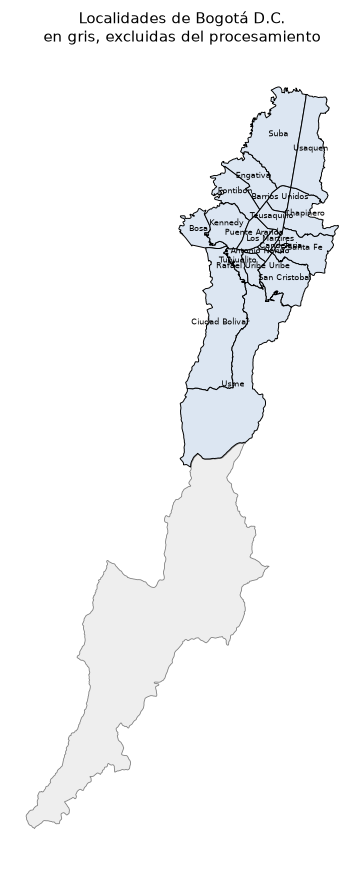

In [4]:
activas = localidades[~localidades["excluida"]].copy()
POLIGONO_CIUDAD = activas.geometry.union_all()

fig, ax = plt.subplots(figsize=(8, 9))
localidades[localidades["excluida"]].plot(ax=ax, facecolor="#EEEEEE",
                                          edgecolor="grey", linewidth=0.6)
activas.plot(ax=ax, facecolor="#DCE6F2", edgecolor="black", linewidth=0.7)
for _, r in activas.iterrows():
    ax.annotate(r["nombre"].title(), (r.geometry.centroid.x, r.geometry.centroid.y),
                ha="center", fontsize=6)
ax.set_title("Localidades de Bogotá D.C.\n"
             "en gris, excluidas del procesamiento", fontsize=11)
ax.set_axis_off()
plt.tight_layout(); plt.show()

---
## 2. Malla Vial Integral de toda la ciudad

Una sola consulta paginada (1.000 ejes por página, ordenados por `OBJECTID`)
sobre la caja que envuelve la ciudad más un margen de 250 m. Cada página se
congela con su hash, y al terminar se escribe un manifiesto con el conteo del
servidor y el hash del conjunto. Si el manifiesto existe, no se consulta el
servidor.

Tres comprobaciones de integridad detienen el proceso si fallan: ninguna página
intermedia incompleta, total leído igual al conteo declarado por el servidor, y
ningún `OBJECTID` repetido entre páginas.

**Sobre el margen:** la malla de Catastro cubre solo el Distrito, así que el
margen casi no agrega ejes (4 quedan fuera del recorte). El grafo termina en el
límite distrital.

In [5]:
t0 = time.time()
malla, bit_malla = d1_malla.descargar_malla_congelada(
    POLIGONO_CIUDAD, margen_m=MARGEN_MALLA_M)
print(f"\nTiempo: {(time.time() - t0)/60:.1f} min")

BITACORA["malla"] = bit_malla

# Fecha de corte: la primera vez se muestra para copiarla en constantes_d1.
# Desde la segunda, se exige que coincida.
if K.FECHA_CORTE_MALLA is None:
    print()
    print("Copie esta linea en constantes_d1.py, en lugar de la actual:")
    print(f'    FECHA_CORTE_MALLA = "{bit_malla["fecha_corte"]}"')
else:
    assert K.FECHA_CORTE_MALLA == bit_malla["fecha_corte"], (
        f"constantes_d1 dice {K.FECHA_CORTE_MALLA} y el crudo congelado es "
        f"del {bit_malla['fecha_corte']}")
    print(f"Fecha de corte verificada: {K.FECHA_CORTE_MALLA}")

Malla Vial v2024: leyendo de disco
  pagina  138    839 ejes  (disco)
  ejes en el crudo            : 138,839
  tras recortar al poligono   : 138,835
  excluidos (peatonal/proyect): 8,362
  ejes finales                : 130,473
  MVICODIGO nulos             : 0
  MVICODIGO repetidos (filas) : 0
  fecha de corte : 2026-09-19
  sha del conjunto: 3d8963916697159423856913110c144661d42abdbc12c67398058dee6a8df75e

Tiempo: 0.3 min
Fecha de corte verificada: 2026-09-19


In [6]:
# Verificacion independiente del congelamiento (regla 3).
# congelar_get verifica con sha256_bytes sobre el contenido en memoria; aqui
# se recalcula por otro camino: leyendo cada archivo de disco por bloques.
from d1_procedencia import sha256_archivo

_carp = K.ruta_cruda() / "congelados"
_man = json.loads((_carp / f"{K.PREFIJO_CRUDO_MALLA}.manifiesto.json")
                  .read_text(encoding="utf-8"))

_malos = [p["nombre"] for p in _man["paginas"]
          if sha256_archivo(_carp / f"{p['nombre']}.geojson") != p["sha256"]]
_suma = sum(p["n_registros"] for p in _man["paginas"])

print(f"Paginas en el manifiesto : {_man['n_paginas']}")
print(f"Hash recalculado distinto: {len(_malos)}")
print(f"Registros (suma paginas) : {_suma:,}   conteo servidor: "
      f"{_man['total_esperado']:,}")

assert not _malos, f"Paginas alteradas: {_malos}"
assert _suma == _man["total_esperado"]
print("Congelamiento verificado: OK")

Paginas en el manifiesto : 139
Hash recalculado distinto: 0
Registros (suma paginas) : 138,839   conteo servidor: 138,839
Congelamiento verificado: OK


In [7]:
# Completitud de los atributos que el modelo de consumo necesita.
print("Declaración de atributos en la malla de la ciudad:")
for campo, etiqueta in (("MVICIV", "Código de Identificación Vial"),
                        ("MVINUMC", "carriles por calzada"),
                        ("MVIVELREG", "velocidad reglamentaria")):
    if campo in malla.columns:
        n = int(malla[campo].notna().sum())
        print(f"  {campo:<11} {etiqueta:<32} {n:>7,} de {len(malla):,} "
              f"({100*n/len(malla):>5.1f} %)")

print()
print("Velocidad reglamentaria por clasificación POT:")
if "MVIVELREG" in malla.columns:
    _v = malla.groupby("clasificacion_pot")["MVIVELREG"].agg(
        declarados=lambda s: int(s.notna().sum()),
        total="size",
        valores_distintos=lambda s: int(s.dropna().nunique()))
    _v["pct"] = (100 * _v["declarados"] / _v["total"]).round(1)
    print(_v.to_string())
    BITACORA["velocidad_reglamentaria"] = _v.to_dict(orient="index")

Declaración de atributos en la malla de la ciudad:
  MVICIV      Código de Identificación Vial    130,473 de 130,473 (100.0 %)
  MVINUMC     carriles por calzada             130,473 de 130,473 (100.0 %)
  MVIVELREG   velocidad reglamentaria           82,729 de 130,473 ( 63.4 %)

Velocidad reglamentaria por clasificación POT:
                   declarados  total  valores_distintos    pct
clasificacion_pot                                             
arterial                 4742  16961                  2   28.0
intermedia               2644  29104                  2    9.1
local                   75009  75009                  2  100.0
rural                      69   3159                  2    2.2
sin_definir               265   6240                  2    4.2


---
## 3. Grafo dirigido

Un solo grafo para toda la ciudad. Los nodos se forman agrupando extremos sobre
una rejilla de 2 m, así que la continuidad entre localidades es automática: dos
ejes de localidades distintas que comparten un extremo quedan unidos sin ninguna
costura especial.

In [8]:
t0 = time.time()
segmentos = d1_malla.construir_grafo_dirigido(
    malla, tolerancia_nodo_m=TOLERANCIA_NODO_M)
print(f"\nTiempo: {(time.time() - t0)/60:.1f} min")

# --- Validacion del identificador estable ---------------------------------
print()
print("=" * 66)
print("VALIDACION DEL segmento_id ESTABLE")
print("=" * 66)

n_resp = int(segmentos["id_por_respaldo"].sum())
n_des = int(segmentos["id_desempatado"].sum())

print(f"Aristas                          : {len(segmentos):,}")
print(f"segmento_id unicos               : {segmentos['segmento_id'].nunique():,}")
print(f"Ejes distintos (id_eje)          : {segmentos['id_eje'].nunique():,}")
print(f"Con id de respaldo por coordenadas: {n_resp:,} "
      f"({100*n_resp/len(segmentos):.2f} %)")
print(f"Desempatados por codigo repetido  : {n_des:,}")
print()
print("Reparto por sentido de recorrido:")
print(segmentos["sentido_recorrido"].value_counts().to_string())
print()
print("Ejemplos de identificador:")
print(segmentos[["segmento_id", "id_eje", "parte", "sentido_recorrido",
                 "name", "highway"]].head(8).to_string(index=False))

# La prueba de fondo: el id NO debe depender de la rejilla de nodos. Se
# reconstruye el grafo con otra tolerancia y los identificadores deben ser
# los mismos. Con el id viejo (u_v_key) esto fallaba por construccion.
print()
print("Invarianza a la tolerancia de nodo (3,0 m en vez de 2,0):")
_alt = d1_malla.construir_grafo_dirigido(malla, tolerancia_nodo_m=3.0,
                                         verboso=False)
_a, _b = set(segmentos["segmento_id"]), set(_alt["segmento_id"])
print(f"  ids con tol=2,0 m : {len(_a):,}")
print(f"  ids con tol=3,0 m : {len(_b):,}")
print(f"  identicos         : {'SI' if _a == _b else 'NO'}")
if _a != _b:
    print(f"  solo en tol=2,0: {len(_a - _b):,}   solo en tol=3,0: {len(_b - _a):,}")
    print("  (si la diferencia es distinta de cero, queda algun id que")
    print("   todavia depende de la rejilla: revisar los de respaldo)")

# Los nodos SI cambian con la tolerancia, y eso esta bien: la topologia
# depende de la rejilla, la identidad de los arcos no.
print(f"  nodos con tol=2,0 : {len(set(segmentos['u']) | set(segmentos['v'])):,}")
print(f"  nodos con tol=3,0 : {len(set(_alt['u']) | set(_alt['v'])):,}")

BITACORA["identificador"] = {
    "esquema": "<MVICODIGO>_<parte>_<FT|TF>",
    "n_aristas": int(len(segmentos)),
    "n_ids_unicos": int(segmentos["segmento_id"].nunique()),
    "n_ejes_distintos": int(segmentos["id_eje"].nunique()),
    "n_id_por_respaldo": n_resp,
    "n_id_desempatado": n_des,
    "invariante_a_tolerancia_nodo": bool(_a == _b),
}
del _alt, _a, _b

Ejes de entrada: 130,473
Aristas dirigidas: 225,704
Nodos distintos: 94,795
Longitud total: 14,909.4 km
Ejes con geometria multiparte: 3
Identificadores de respaldo (sin MVICODIGO): 0
Identificadores desempatados por codigo repetido: 0
Lazos degenerados descartados (< 2.0 m): 86

Aristas por sentido oficial:
  B (doble sentido oficial)        88,730 ejes
  FT (un sentido, directo)         18,593 ejes
  TF (un sentido, inverso)         16,593 ejes
  SD (doble sentido SUPUESTO)      6,187 ejes
  N (doble sentido SUPUESTO)       370 ejes

Tiempo: 0.4 min

VALIDACION DEL segmento_id ESTABLE
Aristas                          : 225,704
segmento_id unicos               : 225,704
Ejes distintos (id_eje)          : 130,387
Con id de respaldo por coordenadas: 0 (0.00 %)
Desempatados por codigo repetido  : 0

Reparto por sentido de recorrido:
sentido_recorrido
FT    113850
TF    111854

Ejemplos de identificador:
segmento_id id_eje  parte sentido_recorrido      name     highway
     1_0_FT      1 

---
## 3b. Diagnóstico de la red para el ruteo

Conectividad débil y fuerte, longitud física de la red, atributos de la fuente
(velocidad, carriles, sentido) con el significado oficial de sus códigos, y
localización de las aristas que quedan fuera de la componente fuertemente
conexa. Nada de esta sección modifica el grafo: solo mide y marca.

In [9]:
conect = d1_malla.diagnostico_conectividad(segmentos)
BITACORA["conectividad"] = conect

Componentes debilmente conexas: 744
Componente mayor: 91,701 nodos (96.7 % del total)
Longitud en la componente mayor: 95.6 %
Tamano de las 5 mayores: [91701, 323, 259, 104, 100]


In [10]:
# =============================================================================
# DIAGNOSTICOS PARA LA FASE DE RUTEO
# =============================================================================
import networkx as nx

# --- 1. Conectividad FUERTE (respeta el sentido de circulacion) -------------
# La debil ignora el sentido. Para rutear hay que poder ir Y volver: un nodo
# al que se entra por una calle de un solo sentido y del que no se sale es una
# trampa para el ruteo, aunque la conectividad debil lo cuente como conectado.
_G = nx.DiGraph()
_G.add_edges_from(zip(segmentos["u"], segmentos["v"]))
_fuertes = sorted(nx.strongly_connected_components(_G), key=len, reverse=True)
_mayor = _fuertes[0]
_n = _G.number_of_nodes()

_en_mayor = (segmentos["u"].isin(list(_mayor))
             & segmentos["v"].isin(list(_mayor)))
_km_mayor = segmentos.loc[_en_mayor, "longitud_m"].sum() / 1000
_km_total = segmentos["longitud_m"].sum() / 1000

print("CONECTIVIDAD FUERTE")
print(f"  componentes fuertemente conexas : {len(_fuertes):,}")
print(f"  nodos en la mayor               : {len(_mayor):,} de {_n:,} "
      f"({100*len(_mayor)/_n:.1f} %)")
print(f"  aristas en la mayor             : {int(_en_mayor.sum()):,} de "
      f"{len(segmentos):,} ({100*_en_mayor.mean():.1f} %)")
print(f"  longitud en la mayor            : {100*_km_mayor/_km_total:.1f} %")
print(f"  tamano de las 5 mayores         : {[len(c) for c in _fuertes[:5]]}")

# --- 2. Km fisicos vs km dirigidos -------------------------------------------
# Una calle de doble sentido aporta dos aristas: la suma de aristas la cuenta
# dos veces. Los km fisicos cuentan cada (eje, parte) una sola vez.
_km_fisicos = (segmentos.drop_duplicates(["id_eje", "parte"])["longitud_m"]
               .sum() / 1000)
print()
print("LONGITUD DE RED")
print(f"  km dirigidos (suma de aristas) : {_km_total:,.1f}")
print(f"  km fisicos de via              : {_km_fisicos:,.1f}")

# --- 3. Valores reales de velocidad, carriles y sentido ----------------------
# Cada clase de via mostro solo 2 velocidades distintas: hay que ver si una
# es un relleno (0, valor por defecto) antes de que el modelo de consumo la use.
print()
print("VELOCIDAD REGLAMENTARIA (MVIVELREG) por clase:")
print(malla.groupby("clasificacion_pot")["MVIVELREG"]
      .value_counts(dropna=False).to_string())
print()
print("CARRILES (MVINUMC), 10 valores mas comunes:")
print(malla["MVINUMC"].value_counts(dropna=False).head(10).to_string())
print()
print("SENTIDO (MVISVIA), todos los valores:")
print(malla["MVISVIA"].value_counts(dropna=False).to_string())

BITACORA["diagnostico_ruteo"] = {
    "n_componentes_fuertes": len(_fuertes),
    "nodos_componente_fuerte_mayor": len(_mayor),
    "fraccion_nodos_fuerte_mayor": round(len(_mayor) / _n, 4),
    "fraccion_aristas_fuerte_mayor": round(float(_en_mayor.mean()), 4),
    "km_dirigidos": round(float(_km_total), 1),
    "km_fisicos": round(float(_km_fisicos), 1),
}
# Marca por arista: True si la arista esta dentro de la componente fuerte
# mayor, es decir, si desde ella se puede llegar a toda la red y volver.
# No se elimina nada: el ruteo filtra por esta columna y el resto se reporta.
segmentos["en_componente_fuerte"] = _en_mayor
del _G

CONECTIVIDAD FUERTE
  componentes fuertemente conexas : 3,871
  nodos en la mayor               : 87,752 de 94,795 (92.6 %)
  aristas en la mayor             : 214,837 de 225,704 (95.2 %)
  longitud en la mayor            : 92.4 %
  tamano de las 5 mayores         : [87752, 323, 310, 259, 102]

LONGITUD DE RED
  km dirigidos (suma de aristas) : 14,909.4
  km fisicos de via              : 8,711.6

VELOCIDAD REGLAMENTARIA (MVIVELREG) por clase:
clasificacion_pot  MVIVELREG
arterial           NaN          12219
                   50            4528
                   30             214
intermedia         NaN          26460
                   30            2516
                   50             128
local              30           74999
                   50              10
rural              NaN           3090
                   30              68
                   50               1
sin_definir        NaN           5975
                   30             184
                   50         

In [11]:
# Significado oficial de los codigos de la capa, desde sus metadatos.
# Se congela con el mismo patron: queda como evidencia de lo que declaraba
# la fuente, y la proxima corrida lo lee de disco.
from d1_procedencia import congelar_get
from d1_red import sesion_http

_res = congelar_get("malla_vial_capa13_metadatos", K.MALLA_SERVICIO,
                    {"f": "json"}, sesion_http(), extension=".json")
_capa = json.loads(_res["contenido"].decode("utf-8"))

for _c in _capa.get("fields", []):
    if _c["name"] in ("MVISVIA", "MVITCLA", "MVIVELREG"):
        print(f"{_c['name']}  ({_c.get('alias')})")
        _dom = _c.get("domain")
        if _dom and _dom.get("codedValues"):
            for _v in _dom["codedValues"]:
                print(f"    {_v['code']!s:<6} -> {_v['name']}")
        else:
            print("    (la capa no declara dominio de codigos para este campo)")
        print()

  [congelado] malla_vial_capa13_metadatos.json  bajado 2026-09-19T13:34:06-05:00  sha ca99384c76c4...
MVITCLA  (Tipo de clasificacion)
    (la capa no declara dominio de codigos para este campo)

MVISVIA  (Sentido de la via)
    FT     -> Desde hacia
    TF     -> Hacia desde
    N      -> Sin sentido
    B      -> Doble Sentido
    SD     -> Sin definir

MVIVELREG  (Velocidad Reglamentaria)
    (la capa no declara dominio de codigos para este campo)



In [12]:
# Marca de pertenencia: el grafo incluye el anillo de margen, las estadisticas no.
segmentos["en_ciudad"] = segmentos.geometry.intersects(POLIGONO_CIUDAD)

# Localidad de cada segmento, por su punto medio. Sirve para desagregar.
medios = gpd.GeoDataFrame(
    {"segmento_id": segmentos["segmento_id"]},
    geometry=segmentos.geometry.interpolate(0.5, normalized=True),
    crs=K.CRS_METRICO)
asignacion = gpd.sjoin(medios, activas[["nombre", "geometry"]],
                       how="left", predicate="within")
asignacion = asignacion.drop_duplicates(subset=["segmento_id"], keep="first")
segmentos = segmentos.merge(
    asignacion[["segmento_id", "nombre"]].rename(columns={"nombre": "localidad"}),
    on="segmento_id", how="left", validate="one_to_one")

ids_ciudad = set(segmentos.loc[segmentos["en_ciudad"], "segmento_id"])

# --- Prueba de cobertura: ninguna localidad activa puede quedar vacia ------
esperadas = set(activas["nombre"])
presentes = set(segmentos["localidad"].dropna())
faltantes = sorted(esperadas - presentes)

por_loc = segmentos.groupby("localidad")["longitud_m"].sum() / 1000
km_por_km2 = (por_loc / activas.set_index("nombre")["area_km2"]).dropna()
sospechosas = sorted(km_por_km2[km_por_km2 < 5].index)

print()
print(f"Localidades activas: {len(esperadas)}   con aristas: {len(presentes)}")
if faltantes:
    print(f"SIN NINGUNA ARISTA: {faltantes}")
if sospechosas:
    print(f"DENSIDAD ANOMALA (<5 km de via por km2): {sospechosas}")
    print(km_por_km2.loc[sospechosas].round(2).to_string())
    print("Una localidad urbana tiene decenas de km de via por km2.")
    print("Un valor bajo indica que solo entraron astillas del margen.")

assert not faltantes, f"Localidades sin aristas: {faltantes}"
assert not sospechosas, f"Localidades con densidad anomala: {sospechosas}"
print("Cobertura por localidad: OK")

print(f"Aristas del grafo        : {len(segmentos):,}")
print(f"Aristas dentro de la ciudad: {len(ids_ciudad):,} "
      f"({100*len(ids_ciudad)/len(segmentos):.1f} %)")
print(f"Longitud total           : {segmentos['longitud_m'].sum()/1000:,.0f} km")
print()
print("Aristas por localidad:")
print(segmentos["localidad"].value_counts().to_string())


Localidades activas: 19   con aristas: 19
Cobertura por localidad: OK
Aristas del grafo        : 225,704
Aristas dentro de la ciudad: 225,646 (100.0 %)
Longitud total           : 14,909 km

Aristas por localidad:
localidad
KENNEDY               27747
CIUDAD BOLIVAR        27675
SUBA                  25804
ENGATIVA              18920
USME                  17754
BOSA                  17357
SAN CRISTOBAL         13893
RAFAEL URIBE URIBE    13740
USAQUEN               12635
PUENTE ARANDA          9235
FONTIBON               9167
TEUSAQUILLO            5483
BARRIOS UNIDOS         5470
CHAPINERO              5369
SANTA FE               4445
TUNJUELITO             3719
LOS MARTIRES           3199
ANTONIO NARIÑO         3088
CANDELARIA              807


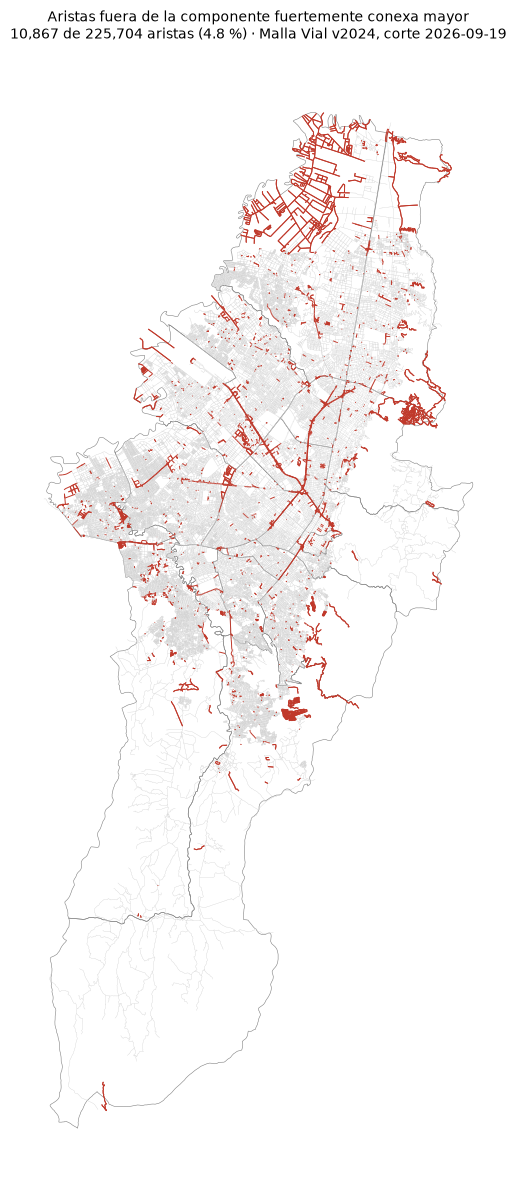

Fuera de la componente fuerte, por localidad:
                    aristas  fuera  pct_fuera
localidad                                    
CHAPINERO              5369    884       16.5
USME                  17754   1573        8.9
TEUSAQUILLO            5483    454        8.3
CANDELARIA              807     65        8.1
SANTA FE               4445    336        7.6
FONTIBON               9167    612        6.7
SUBA                  25804   1543        6.0
SAN CRISTOBAL         13893    762        5.5
BARRIOS UNIDOS         5470    285        5.2
USAQUEN               12635    595        4.7
TUNJUELITO             3719    173        4.7
CIUDAD BOLIVAR        27675   1162        4.2
BOSA                  17357    673        3.9
ENGATIVA              18920    540        2.9
LOS MARTIRES           3199     87        2.7
ANTONIO NARIÑO         3088     78        2.5
KENNEDY               27747    555        2.0
PUENTE ARANDA          9235    188        2.0
RAFAEL URIBE URIBE    13740    227

In [13]:
# =============================================================================
# DONDE ESTAN LAS ARISTAS FUERA DE LA COMPONENTE FUERTE, Y DE QUE TIPO SON
# Si se concentran en bordes rurales o zonas de ladera, es estructura real de
# la red. Si estan dispersas, apunta a errores de sentido en la fuente.
# =============================================================================
_dentro = segmentos["en_componente_fuerte"].astype(bool)
_fuera = segmentos[~_dentro]

fig, ax = plt.subplots(figsize=(10, 12))
activas.boundary.plot(ax=ax, color="grey", linewidth=0.4)
segmentos[_dentro].plot(ax=ax, color="#D5D5D5", linewidth=0.15)
_fuera.plot(ax=ax, color="#C0392B", linewidth=0.7)
ax.set_title("Aristas fuera de la componente fuertemente conexa mayor\n"
             f"{len(_fuera):,} de {len(segmentos):,} aristas "
             f"({100*len(_fuera)/len(segmentos):.1f} %) · Malla Vial "
             f"v{K.MALLA_PRODUCCION_VERSION}, corte {K.FECHA_CORTE_MALLA}",
             fontsize=10)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(K.ruta_figura("D2_aristas_fuera_componente_fuerte.png"),
            dpi=150, bbox_inches="tight")
plt.show()

def _tabla_fuera(col):
    t = (segmentos.groupby(col)["en_componente_fuerte"]
         .agg(aristas="size", fuera=lambda s: int((~s.astype(bool)).sum())))
    t["pct_fuera"] = (100 * t["fuera"] / t["aristas"]).round(1)
    return t.sort_values("pct_fuera", ascending=False)

print("Fuera de la componente fuerte, por localidad:")
print(_tabla_fuera("localidad").to_string())
print()
print("Por clase de via:")
print(_tabla_fuera("highway").to_string())
print()
print("Por sentido oficial:")
print(_tabla_fuera("sentido_oficial").to_string())

# --- Sentido supuesto: cuanto pesa en la red ---------------------------------
_sup = segmentos["sentido_supuesto"].astype(bool)
print()
print(f"Aristas con sentido SUPUESTO (SD/N): {int(_sup.sum()):,} "
      f"({100*_sup.mean():.1f} %)")
print(f"  de ellas fuera de la componente fuerte: "
      f"{int((_sup & ~_dentro).sum()):,}")

# --- Los ejes multiparte ------------------------------------------------------
_multi = (segmentos.groupby("id_eje")["parte"].nunique()
          .loc[lambda s: s > 1])
print()
print(f"Ejes multiparte: {len(_multi)}")
for _eje, _n in _multi.items():
    _nom = segmentos.loc[segmentos["id_eje"] == _eje, "name"].dropna()
    print(f"  MVICODIGO {_eje}: {_n} partes  "
          f"({_nom.iloc[0] if len(_nom) else 'sin nombre'})")

BITACORA["fuera_componente_fuerte"] = {
    "n_aristas": int(len(_fuera)),
    "por_clase": _tabla_fuera("highway")["fuera"].to_dict(),
    "n_sentido_supuesto": int(_sup.sum()),
    "n_sentido_supuesto_fuera": int((_sup & ~_dentro).sum()),
    "ejes_multiparte": {str(k): int(v) for k, v in _multi.items()},
}

In [14]:
from shapely.geometry import Point

extremos = []
for _, f in segmentos.iterrows():
    c = list(f.geometry.coords)
    extremos.append({"nodo_id": f["u"], "x": c[0][0],  "y": c[0][1]})
    extremos.append({"nodo_id": f["v"], "x": c[-1][0], "y": c[-1][1]})

nodos = (pd.DataFrame(extremos)
         .groupby("nodo_id", as_index=False)[["x", "y"]].mean())

nodos = gpd.GeoDataFrame(
    nodos, geometry=gpd.points_from_xy(nodos["x"], nodos["y"]),
    crs=K.CRS_METRICO)

nodos_wgs = nodos.to_crs(K.CRS_GEOGRAFICO)
nodos["lon"] = nodos_wgs.geometry.x
nodos["lat"] = nodos_wgs.geometry.y

sal_nodos = K.ruta_entregable("D2", "nodos_bogota.gpkg")
nodos.to_file(sal_nodos, layer="nodos", driver="GPKG")
nodos.drop(columns="geometry").to_csv(
    K.ruta_entregable("D2", "nodos_bogota.csv"), index=False)

print(f"Nodos: {len(nodos):,}")
print(nodos[["nodo_id", "x", "y", "lon", "lat"]].head().to_string(index=False))

Nodos: 94,795
        nodo_id            x            y        lon      lat
2432078_1034353 4.864156e+06 2.068707e+06 -74.225148 4.620765
2432325_1019794 4.864649e+06 2.039588e+06 -74.220262 4.357297
2432446_1019367 4.864892e+06 2.038734e+06 -74.218062 4.349575
2432507_1034081 4.865015e+06 2.068162e+06 -74.217395 4.615850
2432542_1034157 4.865084e+06 2.068314e+06 -74.216773 4.617226


---
## 4. Exportación para el frente de pendiente

Diez pruebas antes de escribir; relectura desde disco después de escribir.
Salidas en `entregables/D2/`: segmentos (GeoPackage y CSV), nodos, contrato de
intercambio y huellas. El contrato declara las columnas y reglas que debe
cumplir el archivo de pendiente; el cuaderno D3 las verifica al recibirlo.

In [ ]:
# =============================================================================
# EXPORTACION PARA EL MODULO DE TERRENO Y PENDIENTE
# Este cuaderno termina aqui. La pendiente vuelve unida por segmento_id.
# =============================================================================
import re
from d1_procedencia import huella_segmentos, sha256_archivo

COLUMNAS_EXPORTA = ["segmento_id", "id_eje", "parte", "sentido_recorrido",
                    "u", "v", "oneway", "highway", "calzada", "civ", "name",
                    "id_por_respaldo", "id_desempatado", "en_ciudad",
                    "localidad", "en_componente_fuerte", "sentido_oficial",
                    "sentido_supuesto", "longitud_m", "geometry"]

# Orden fijo por id: el mismo contenido produce siempre el mismo CSV.
exporta = (segmentos[[c for c in COLUMNAS_EXPORTA if c in segmentos.columns]]
           .sort_values("segmento_id").reset_index(drop=True))
exporta = gpd.GeoDataFrame(exporta, geometry="geometry", crs=segmentos.crs)
exporta["segmento_id"] = exporta["segmento_id"].astype("string")

# -----------------------------------------------------------------------------
# PRUEBAS ANTES DE ENTREGAR
# -----------------------------------------------------------------------------
def _id_nodo(x, y, tol=K.TOLERANCIA_NODO_M):
    # Formula del documento de parametros, escrita de nuevo AQUI y no
    # importada de d1_malla: asi la prueba es un camino independiente.
    return f"{int(round(x / tol))}_{int(round(y / tol))}"

pruebas_export = []

# 1. Identificador unico
pruebas_export.append({
    "prueba": "segmento_id unico",
    "n_segmentos": len(exporta),
    "pasa": bool(exporta["segmento_id"].is_unique)})

# 2. Formato <MVICODIGO>_<parte>_<FT|TF>, con #n solo si fue desempatado
_fmt = exporta["segmento_id"].str.match(r"^.+_\d+_(FT|TF)(#\d+)?$")
_con_punto_cero = (exporta["segmento_id"].str.contains(".0_", regex=False)
                   | exporta["id_eje"].astype(str).str.endswith(".0"))
pruebas_export.append({
    "prueba": "formato de segmento_id y sin '.0'",
    "n_formato_invalido": int((~_fmt).sum()),
    "n_con_punto_cero": int(_con_punto_cero.sum()),
    "pasa": bool(_fmt.all() and not _con_punto_cero.any())})

# 3. u y v coinciden con el PRIMER y el ULTIMO punto de la geometria.
#    Es la prueba mas importante para el modulo de terreno: garantiza que la geometria esta
#    dibujada en el sentido de recorrido, asi que su pendiente saldra con el
#    signo correcto (positiva = sube de u hacia v).
_ini = [g.coords[0] for g in exporta.geometry]
_fin = [g.coords[-1] for g in exporta.geometry]
_u_mal = int((exporta["u"].astype(str).to_numpy()
              != np.array([_id_nodo(x, y) for x, y, *_ in _ini])).sum())
_v_mal = int((exporta["v"].astype(str).to_numpy()
              != np.array([_id_nodo(x, y) for x, y, *_ in _fin])).sum())
pruebas_export.append({
    "prueba": "u/v = extremos de la geometria (sentido)",
    "n_u_distinto": _u_mal, "n_v_distinto": _v_mal,
    "pasa": _u_mal == 0 and _v_mal == 0})

# 4. Sentido: un eje de doble sentido da 2 filas por parte; uno unico, 1.
_g = (exporta.groupby(["id_eje", "parte"])
      .agg(n=("segmento_id", "size"),
           unico=("oneway", "first"),
           desemp=("id_desempatado", "any")))
_g = _g[~_g["desemp"].astype(bool)]   # los desempatados se cuentan aparte
_esperado = np.where(_g["unico"].astype(bool), 1, 2)
_mal_sentido = int((_g["n"].to_numpy() != _esperado).sum())
pruebas_export.append({
    "prueba": "filas por eje segun sentido oficial",
    "n_ejes_parte": int(len(_g)), "n_incoherentes": _mal_sentido,
    "pasa": _mal_sentido == 0})

# 5. Longitud: la columna es la de la geometria, y ninguna bajo el minimo
_dif = (exporta.geometry.length - exporta["longitud_m"]).abs().max()
pruebas_export.append({
    "prueba": "longitud_m = largo de la geometria y >= minimo",
    "dif_maxima_m": float(_dif),
    "longitud_minima_m": float(exporta["longitud_m"].min()),
    "pasa": bool(_dif < 1e-6
                 and exporta["longitud_m"].min() >= K.LONGITUD_MINIMA_LAZO_M)})

# 6. Longitud proyectada vs geodesica (camino de calculo distinto)
pruebas_export.append(B.verificar_longitudes_muestreado(exporta, n=5000))

# 7. CRS y clases de via
_permitidas = {d1_malla.CLASIFICACION_POT[c] for c in K.CLASES_VEHICULO}
_clases = set(exporta["highway"].dropna())
pruebas_export.append({
    "prueba": "CRS 9377 y solo clases vehiculares",
    "epsg": exporta.crs.to_epsg(),
    "clases_fuera": sorted(_clases - _permitidas),
    "n_sin_clase": int(exporta["highway"].isna().sum()),
    "pasa": (exporta.crs.to_epsg() == 9377 and _clases <= _permitidas
             and exporta["highway"].notna().all())})

# 8. Los nodos de los segmentos son exactamente los del archivo de nodos
_nod_seg = set(exporta["u"].astype(str)) | set(exporta["v"].astype(str))
_nod_arch = set(nodos["nodo_id"].astype(str))
pruebas_export.append({
    "prueba": "nodos de segmentos = archivo de nodos",
    "solo_en_segmentos": len(_nod_seg - _nod_arch),
    "solo_en_nodos": len(_nod_arch - _nod_seg),
    "pasa": _nod_seg == _nod_arch})

# 9. Las aristas marcadas en_componente_fuerte forman UN solo grafo
#    fuertemente conexo. Se reconstruye el grafo solo con las marcadas, por
#    un camino distinto al que produjo la marca.
import networkx as nx
_marcadas = exporta[exporta["en_componente_fuerte"].astype(bool)]
_Gf = nx.DiGraph()
_Gf.add_edges_from(zip(_marcadas["u"], _marcadas["v"]))
pruebas_export.append({
    "prueba": "marcadas en_componente_fuerte = un grafo fuertemente conexo",
    "n_aristas_marcadas": int(len(_marcadas)),
    "pasa": bool(len(_marcadas) > 0 and nx.is_strongly_connected(_Gf))})
del _Gf

# 10. sentido_supuesto marca exactamente los ejes sin sentido oficial
#     (SD "Sin definir", N "Sin sentido" o vacio), y ninguno de ellos puede
#     haber quedado como calle de un solo sentido.
_ofi = exporta["sentido_oficial"].fillna("").astype(str).str.upper()
_esp_sup = ~_ofi.isin(["FT", "TF", "B"])
_sup_e = exporta["sentido_supuesto"].astype(bool)
_sup_unico = int((_sup_e & exporta["oneway"].astype(bool)).sum())
pruebas_export.append({
    "prueba": "sentido_supuesto = ejes sin sentido oficial (SD, N)",
    "n_aristas_supuestas": int(_sup_e.sum()),
    "n_discrepancias": int((_sup_e != _esp_sup).sum()),
    "n_supuestas_de_un_sentido": _sup_unico,
    "pasa": bool((_sup_e == _esp_sup).all() and _sup_unico == 0)})

print(d1.resumen_pruebas(pruebas_export).to_string(index=False))
_fallan = [p["prueba"] for p in pruebas_export if not p["pasa"]]
assert not _fallan, f"NO se exporta. Fallan: {_fallan}"

# -----------------------------------------------------------------------------
# ESCRITURA
# -----------------------------------------------------------------------------
sal_seg_gpkg = K.ruta_entregable("D2", "D2_segmentos_para_pendiente.gpkg")
sal_seg_csv  = K.ruta_entregable("D2", "D2_segmentos_para_pendiente.csv")
sal_contrato = K.ruta_entregable("D2", "D2_contrato_intercambio.json")
sal_huellas  = K.ruta_entregable("D2", "D2_huellas_salidas.json")
sal_bit      = K.ruta_entregable("D2", "bitacora_ejecucion_D2.json")
sal_nod_csv  = K.ruta_entregable("D2", "nodos_bogota.csv")

# Se borra el .gpkg anterior: escribir sobre uno existente puede dejar capas
# viejas dentro del mismo archivo.
if sal_seg_gpkg.exists():
    sal_seg_gpkg.unlink()
exporta.to_file(sal_seg_gpkg, layer="segmentos", driver="GPKG")
exporta.drop(columns="geometry").to_csv(sal_seg_csv, index=False,
                                        encoding="utf-8")

# --- Relectura desde disco: lo escrito es lo que se probo -------------------
huella = huella_segmentos(exporta)
_rel_gpkg = gpd.read_file(sal_seg_gpkg, layer="segmentos")
_rel_csv = pd.read_csv(sal_seg_csv, dtype={"segmento_id": "string",
                                           "id_eje": "string",
                                           "u": "string", "v": "string"})
assert huella_segmentos(_rel_gpkg) == huella, "El gpkg releido no es igual"
assert _rel_gpkg.crs.to_epsg() == 9377
assert set(_rel_csv["segmento_id"]) == set(exporta["segmento_id"])
assert len(_rel_csv) == len(exporta)
print("\nRelectura desde disco: OK (gpkg y csv)")

# --- Contrato de intercambio -------------------------------------------------
# Sin hora de ejecucion: si la tuviera, cambiaria el hash en cada corrida.
contrato = {
    "producido_por": "Jhonny - frente grafo (D2)",
    "consumido_por": "Danna - frente terreno y pendiente",
    "crs": "EPSG:9377",
    "malla": {"version": K.MALLA_PRODUCCION_VERSION,
              "fecha_corte": K.FECHA_CORTE_MALLA,
              "sha256_conjunto_crudo": BITACORA["malla"]["sha256_conjunto"]},
    "segmentos": {"archivo_geometria": sal_seg_gpkg.name,
                  "capa": "segmentos",
                  "archivo_tabla": sal_seg_csv.name,
                  "n_segmentos": int(len(exporta)),
                  "huella_contenido": huella,
                  "como_verificar": "d1_procedencia.huella_segmentos(gdf)"},
    "convenciones": {
        "segmento_id": K.FORMATO_SEGMENTO_ID,
        "id_nodo": "f'{round(x/2.0)}_{round(y/2.0)}' en EPSG:9377",
        "sentido": "la geometria va de u a v; FT = sentido de "
                   "digitalizacion del eje, TF = contrario",
        "signo_pendiente": "positiva = sube en el sentido de recorrido "
                           "de esa fila (de u hacia v)",
        "unidades_pendiente": "PORCENTAJE (8.0 = 8 %), nunca fraccion",
        "en_componente_fuerte": "True si la arista pertenece a la componente "
                                "fuertemente conexa mayor (se puede ir y "
                                "volver respetando sentidos). Calcular la "
                                "pendiente de TODAS; el ruteo filtra despues",
        "sentido_supuesto": "True si el eje no tiene sentido oficial (SD "
                            "'Sin definir' o N 'Sin sentido'): se crearon las "
                            "dos direcciones por supuesto. Calcular pendiente "
                            "de ambas"},
    "retorno_esperado": {
        "formato": "CSV UTF-8, separador coma, punto decimal",
        "union_por": ("segmento_id EXACTO de este archivo, sin recalcularlo. "
                      "Una fila por cada segmento, sin borrar ninguna"),
        "columnas": K.COLUMNAS_RETORNO_PENDIENTE,
        "reglas": [
            "Pendientes en PORCENTAJE (8.0 = 8 %)",
            "z_inicio_m = elevacion en el PRIMER punto de la geometria (nodo u); "
            "z_fin_m = elevacion en el ULTIMO punto (nodo v). No invertir la "
            "geometria: ya va en el sentido de recorrido de cada fila",
            "longitud_m = la columna longitud_m del GeoPackage entregado. NO "
            "recalcularla: todas las formulas usan esa longitud",
            "pendiente_neta_pct = 100 * (z_fin_m - z_inicio_m) / longitud_m",
            "pendiente_acumulada_pct = 100 * (ganancia_elevacion_m + "
            "perdida_elevacion_m) / longitud_m",
            "Si falta elevacion en un extremo: pendiente_neta_pct, "
            "clasificacion_invias, error_pendiente_pct y "
            "distinta_de_cero_2sigma VACIOS, y fuera_cobertura_mdt = True",
            "distinta_de_cero_2sigma = |pendiente_neta_pct| > 2 * "
            "error_pendiente_pct. NO es criterio para descartar segmentos: "
            "una calle plana medida como plana es un dato valido",
            "INVIAS sobre |pendiente_neta_pct|: < 3 Plano; [3, 6) Ondulado; "
            "[6, 8] Montañoso; > 8 Escarpado. Etiquetas EXACTAS, con "
            "mayuscula inicial y con ñ: 'Plano', 'Ondulado', 'Montañoso', "
            "'Escarpado'",
            "sigma_z_m y ancho_correlacion_m: un solo valor en todo el archivo",
            "rho_correlacion = exp(-longitud_m / ancho_correlacion_m)",
            "error_pendiente_pct = 100 * sqrt(2 * sigma_z_m^2 * "
            "(1 - rho_correlacion)) / longitud_m",
            "ruido_acumulada_pct = PISO DE RUIDO de la acumulada: la "
            "acumulada que produciria el error del MDT por si solo en una "
            "calle plana. Con p = longitud_m / (n_puntos_muestreados - 1) y "
            "sd = sigma_z_m * sqrt(2 * (1 - exp(-p / ancho_correlacion_m))): "
            "ruido_acumulada_pct = 100 * sqrt(2/pi) * sd / p. La acumulada "
            "no tiene barra +/- porque el ruido en valor absoluto siempre "
            "suma: la infla, no la dispersa. Vacio si n_puntos_muestreados < 2",
            f"pendiente_extrema = max(|pendiente_neta_pct|, "
            f"|pendiente_acumulada_pct|) > {K.UMBRAL_PENDIENTE_EXTREMA_PCT}. "
            "Cota de plausibilidad: la calle mas empinada registrada tiene "
            "34,8 %. Por encima de ese valor la pendiente es poco plausible "
            "pero no necesariamente falsa: marca valores de baja confianza, "
            "que pueden ser calles reales, vias no visibles, escaleras o "
            "errores del MDT. Si la neta esta vacia, se usa solo la "
            "acumulada. No detecta todos los puentes",
            "ganancia_elevacion_m = suma de las subidas y perdida_elevacion_m "
            "= suma de las bajadas a lo largo del perfil muestreado, en "
            "metros, AMBAS positivas",
            "Columnas booleanas (distinta_de_cero_2sigma, pendiente_extrema, "
            "fuera_cobertura_mdt) escritas como True / False",
            f"sigma_z_m = {K.SIGMA_Z_ADOPTADO_M} m (constantes_d1.SIGMA_Z_ADOPTADO_M). "
            "RMSEz contra 496 vertices de la Red de Control Vertical del IGAC con "
            "coordenada calculada. Criterio: guia ASPRS (Flood, 2004, sec. 2.6.1): "
            "errores > 3 sigma se investigan y solo se excluyen con evidencia en el "
            "vertice (adoptado 2026-10-13)",
            f"ancho_correlacion_m = "
            f"{K.RAMAS_PENDIENTE[K.RAMA_OFICIAL]['ancho_correlacion_m']} m "
            "(A del modelo exponencial = rango exponencial / 3)",
        ]},
}
sal_contrato.write_text(json.dumps(contrato, indent=2, ensure_ascii=False),
                        encoding="utf-8")

# --- Huellas de salidas -------------------------------------------------------
huellas = {
    "archivos": {p.name: sha256_archivo(p)
                 for p in (sal_seg_csv, sal_nod_csv, sal_contrato)},
    "contenido": {sal_seg_gpkg.name: huella},
    "nota": ("Los .gpkg se verifican por huella de contenido, no por el "
             "sha256 del archivo, porque guardan su hora de escritura."),
}
sal_huellas.write_text(json.dumps(huellas, indent=2, ensure_ascii=False),
                       encoding="utf-8")

# --- Bitacora (esta SI lleva hora: es un registro, no un dato) ----------------
BITACORA["pruebas_exportacion"] = pruebas_export
BITACORA["ejecucion_terminada"] = d1.sello_de_tiempo()
with open(sal_bit, "w", encoding="utf-8") as f:
    json.dump(BITACORA, f, indent=2, ensure_ascii=False, default=str)

print("\nEscrito:")
for p in (sal_seg_gpkg, sal_seg_csv, sal_nod_csv, sal_contrato,
          sal_huellas, sal_bit):
    print(f"  {p.name:<42} {p.stat().st_size/1e6:>8.2f} MB")
print(f"\nHuella de contenido de los segmentos:\n  {huella}")

                                                     prueba resultado                                                                                                                       detalle
                                          segmento_id unico      PASA                                                                                                            n_segmentos=225704
                          formato de segmento_id y sin '.0'      PASA                                                                                      n_formato_invalido=0, n_con_punto_cero=0
                   u/v = extremos de la geometria (sentido)      PASA                                                                                                n_u_distinto=0, n_v_distinto=0
                        filas por eje segun sentido oficial      PASA                                                                                         n_ejes_parte=130424, n_incoherentes=0
             longitu

---
## 5. Limitaciones declaradas

**1. El grafo termina en el límite del Distrito.** La Malla Vial de Catastro no
incluye municipios vecinos. Las rutas que salen de Bogotá (Soacha, Cota, Chía)
no se modelan.

**2. Sentido supuesto en SD y N.** 6.557 ejes no tienen sentido oficial (SD "Sin
definir", N "Sin sentido", según el dominio de la capa). Se crearon ambas
direcciones y se marcaron con `sentido_supuesto`. Para la alcanzabilidad el
supuesto es optimista: puede habilitar rutas no permitidas. El ruteo se corre
con y sin estas aristas.

**3. Componente fuertemente conexa.** El 95,2 % de las aristas pertenece a la
componente en la que se puede ir y volver respetando sentidos. El resto se
marca (`en_componente_fuerte`) y se reporta; no se elimina. La sección de
diagnóstico muestra dónde está y de qué tipo es.

**4. La velocidad reglamentaria no describe la circulación.** `MVIVELREG` solo
toma los valores 30 y 50, falta en el 72 % de las arterias y la capa no declara
su dominio. No se usa como velocidad de operación en el modelo de consumo.

**5. Longitud de red.** 14.909 km suman las aristas dirigidas (una vía de doble
sentido cuenta dos veces). La red física mide 8.711,6 km.

**6. Localidad por punto medio.** Un segmento que cruza el límite entre dos
localidades se asigna entero a una. Sirve para resúmenes, no para contabilidad
exacta de kilómetros por localidad.

**7. Ejes multiparte.** Tres ejes de la fuente llegan fragmentados en varias
partes; cada parte es un segmento con sus propios nodos. Se listan en la
sección de diagnóstico.

**8. Puentes y deprimidos.** La malla no declara qué ejes son elevados o
deprimidos. El MDT es terreno desnudo, así que la pendiente de esos tramos
puede reflejar el suelo y no la vía. Queda a cargo del frente de pendiente
marcarlos.

**9. Crudos no redescargables.** El servicio no admite consulta histórica. Los
resultados solo se reproducen con la carpeta de crudos congelados del
2026-09-19 (hash del conjunto en el manifiesto).

In [16]:
import geopandas as gpd
import constantes_d1 as K

print("Crudos:", K.ruta_cruda())
for p in sorted(K.ruta_cruda().rglob("*")):
    if p.is_file() and p.suffix.lower() in (".gpkg", ".geojson", ".parquet", ".json", ".shp"):
        print(" ", p.relative_to(K.ruta_cruda()), f"{p.stat().st_size/1e6:.1f} MB")

Crudos: F:\Tesis\Grafo Bogotá\datos_crudos
  congelados\D_localidades_bogota_fuente0.geojson 2.4 MB
  congelados\D_localidades_bogota_fuente0.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024.manifiesto.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_conteo.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_conteo.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_p0000.geojson 0.6 MB
  congelados\D_malla_vial_capa13_v2024_p0000.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_p0001.geojson 0.6 MB
  congelados\D_malla_vial_capa13_v2024_p0001.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_p0002.geojson 0.6 MB
  congelados\D_malla_vial_capa13_v2024_p0002.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_p0003.geojson 0.6 MB
  congelados\D_malla_vial_capa13_v2024_p0003.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_p0004.geojson 0.6 MB
  congelados\D_malla_vial_capa13_v2024_p0004.meta.json 0.0 MB
  congelados\D_malla_vial_capa13_v2024_p0005.geo

In [17]:
import constantes_d1 as K

RAIZ = K.ruta_entregable("D2", "_").parent.parent.parent   # sube hasta F:\Tesis\Grafo Bogotá
print("Buscando desde:", RAIZ)
print()
for p in sorted(RAIZ.rglob("*.csv")):
    if "pendiente" in p.name.lower() or "segmento" in p.name.lower():
        print(f"{p}   ({p.stat().st_size/1e6:.1f} MB)")

Buscando desde: F:\Tesis\Grafo Bogotá

F:\Tesis\Grafo Bogotá\datos_crudos\recibidos\bogota_pendientes_segmentos_mdt2020_v1.csv   (44.6 MB)
F:\Tesis\Grafo Bogotá\datos_crudos\recibidos\bogota_pendientes_segmentos_mdt2020_v1_1.csv   (44.6 MB)
F:\Tesis\Grafo Bogotá\datos_crudos\recibidos\medellin_pendientes_segmentos_dtm2021_v2.csv   (8.5 MB)
F:\Tesis\Grafo Bogotá\datos_crudos\recibidos\pendiente_para_jhonny_sigma0538_20260920_175844.csv   (44.2 MB)
F:\Tesis\Grafo Bogotá\datos_crudos\recibidos\pendiente_para_jhonny_sigma101_20260920_182450.csv   (43.9 MB)
F:\Tesis\Grafo Bogotá\entregables\D2\D2_segmentos_para_pendiente.csv   (33.9 MB)
F:\Tesis\Grafo Bogotá\entregables\D2_medellin\D2M_segmentos_para_pendiente.csv   (11.4 MB)
F:\Tesis\Grafo Bogotá\entregables\D2_respaldo_20261031\D2_segmentos_para_pendiente.csv   (33.9 MB)
F:\Tesis\Grafo Bogotá\entregables\D3\rama_sigma0533_v1\D3_grafo_con_pendiente_sigma0533_v1.csv   (75.3 MB)
F:\Tesis\Grafo Bogotá\entregables\D3\rama_sigma0536_v1_1\D3_gra

In [18]:
import geopandas as gpd
import pandas as pd
import fiona
import constantes_d1 as K

# --- 1. Malla vial cruda (139 páginas congeladas) ------------------------
CONGELADOS = K.ruta_cruda() / "congelados"
paginas = sorted(CONGELADOS.glob("D_malla_vial_capa13_v2024_p*.geojson"))
print(f"Páginas encontradas: {len(paginas)}")
assert paginas, f"No hay páginas de malla en {CONGELADOS}"

malla = pd.concat([gpd.read_file(p) for p in paginas], ignore_index=True)
malla = gpd.GeoDataFrame(malla, geometry="geometry", crs="EPSG:4326")
print(f"Ejes cargados: {len(malla):,}")
print("Campos MVI:", [c for c in malla.columns if c.startswith("MVI")])

# --- 2. Segmentos del grafo (sin pendiente, no hace falta aquí) ----------
RUTA_SEG = K.ruta_entregable("D2", "D2_segmentos_para_pendiente.gpkg")
capas = fiona.listlayers(RUTA_SEG)
print(f"\nCapas en {RUTA_SEG.name}: {capas}")
segmentos = gpd.read_file(RUTA_SEG, layer=capas[0])
segmentos["segmento_id"] = segmentos["segmento_id"].astype("string")
print(f"Segmentos: {len(segmentos):,}")
print("Columnas:", [c for c in segmentos.columns])

Páginas encontradas: 139
Ejes cargados: 138,839
Campos MVI: ['MVICODIGO', 'MVICCALZAD', 'MVICIV', 'MVICCAT', 'MVITCLA', 'MVITIPO', 'MVINOMBRE', 'MVINALTERN', 'MVINPRINCI', 'MVINGENERA', 'MVINANTIGU', 'MVIETIQUET', 'MVISVIA', 'MVINUMC', 'MVIVELREG']

Capas en D2_segmentos_para_pendiente.gpkg: ['segmentos']
Segmentos: 225,704
Columnas: ['segmento_id', 'id_eje', 'parte', 'sentido_recorrido', 'u', 'v', 'oneway', 'highway', 'calzada', 'civ', 'name', 'id_por_respaldo', 'id_desempatado', 'en_ciudad', 'localidad', 'en_componente_fuerte', 'sentido_oficial', 'sentido_supuesto', 'longitud_m', 'geometry']


In [ ]:
# --- Auditoría de tramos con pendiente extrema ---------------------------
CASOS = {
    "126744_0": (4.536616, -74.100205),
    "35231_0":  (4.542215, -74.103319),
    # agrega 130281_0 cuando llegue su coordenada
}
RADIO_M = 40.0

print("Campos disponibles en la malla:")
print([c for c in malla.columns if c.startswith("MVI")])
print()

malla_m = malla.to_crs(K.CRS_METRICO)
seg_m   = segmentos.to_crs(K.CRS_METRICO)   # si aún no existe, corre antes su celda

for etiqueta, (lat, lon) in CASOS.items():
    punto = (gpd.GeoSeries([gpd.points_from_xy([lon], [lat])[0]], crs="EPSG:4326")
             .to_crs(K.CRS_METRICO).iloc[0])
    print("=" * 70)
    print(f"{etiqueta}  ({lat}, {lon})")

    cerca = malla_m[malla_m.distance(punto) <= RADIO_M].copy()
    cerca["dist_m"] = cerca.distance(punto).round(1)
    if cerca.empty:
        print(f"  Ningún eje de la malla a menos de {RADIO_M:.0f} m.")
    else:
        cols = [c for c in ("MVICODIGO", "MVICIV", "MVITCLA", "MVINOMBRE",
                            "MVITIPO", "MVIESTADO", "dist_m") if c in cerca.columns]
        cerca["largo_m"] = cerca.geometry.length.round(1)
        print(cerca[cols + ["largo_m"]].sort_values("dist_m").to_string(index=False))

    mios = seg_m[seg_m.distance(punto) <= RADIO_M]
    if not mios.empty:
        print("\n  Mis segmentos ahí:")
        print(mios[["segmento_id", "longitud_m"]].to_string(index=False))

Campos disponibles en la malla:
['MVICODIGO', 'MVICCALZAD', 'MVICIV', 'MVICCAT', 'MVITCLA', 'MVITIPO', 'MVINOMBRE', 'MVINALTERN', 'MVINPRINCI', 'MVINGENERA', 'MVINANTIGU', 'MVIETIQUET', 'MVISVIA', 'MVINUMC', 'MVIVELREG']

126744_0  (4.536616, -74.100205)
 MVICODIGO   MVICIV  MVITCLA MVINOMBRE MVITIPO  dist_m  largo_m
    112359 18006772        3   SIN_NMG      CL     0.0     36.6
    126744 18006778        3   SIN_NMG      KR     0.0     16.0
    137471 18006771        3   SIN_NMG      KR     0.0     34.5
    106900 18006779        3   SIN_NMG      CL    15.9     33.8
     40360 18006777        3   SIN_NMG      CL    34.2     27.2
     35569 18006760        3   SIN_NMG      CL    34.4     20.6
     39759 18006759        3   SIN_NMG      KR    34.6     43.9
    115870 18006766        3   SIN_NMG      KR    35.7     19.4
    137464 18006756        3   SIN_NMG      CL    36.7     37.0
    137512 18006755        3   SIN_NMG      KR    36.7     28.3
    137501 18006767        3   SIN_NMG   

In [20]:
print(malla.MVITCLA.value_counts().to_string())
print()
print(pd.crosstab(malla.MVITCLA, malla.MVICIV.eq(0), rownames=["clase"],
                  colnames=["CIV = 0"]))

MVITCLA
3    75009
2    29104
1    16961
4     8101
6     6240
5     3163
7      261

CIV = 0  False  True 
clase                
1        16950     11
2        29101      3
3        74781    228
4         7922    179
5         3163      0
6         4775   1465
7          260      1


In [21]:
import json, constantes_d1 as K
meta = json.loads((K.ruta_cruda() / "congelados" /
                   "malla_vial_capa13_metadatos.json").read_text(encoding="utf-8"))
print(json.dumps(meta, indent=2, ensure_ascii=False)[:4000])

{
  "currentVersion": 11.3,
  "cimVersion": "3.3.0",
  "id": 13,
  "name": "Malla Vial",
  "type": "Feature Layer",
  "description": "Layer que representa la clasificación de acuerdo al tipo de tráfico que soporta dentro objeto geográfico Malla Vial.",
  "geometryType": "esriGeometryPolyline",
  "sourceSpatialReference": {
    "wkid": 4326,
    "latestWkid": 4326,
    "xyTolerance": 8.98315284119521e-09,
    "zTolerance": 0.001,
    "mTolerance": 0.001,
    "falseX": -400,
    "falseY": -400,
    "xyUnits": 999999999.9999999,
    "falseZ": 0,
    "zUnits": 1,
    "falseM": 0,
    "mUnits": 1
  },
  "copyrightText": "Secretaría Distrital de Movilidad - SDM, Instituto De Desarrollo Urbano - IDU, Unidad Administrativa Especial de Catastro Distrital - UAECD, Secretaría Distrital de Planeación - SDP",
  "parentLayer": {
    "id": 10,
    "name": "Malla Vial Integral"
  },
  "subLayers": [],
  "minScale": 10000,
  "maxScale": 0,
  "drawingInfo": {
    "renderer": {
      "type": "uniqueValue

In [22]:
# ¿Cuánto cambia si se excluye la clase 6?
sin6 = malla[malla.MVITCLA.isin({1, 2, 3, 5})]
print(f"Ejes con clase 6 : {len(malla[malla.MVITCLA.isin({1,2,3,5,6})]):,}")
print(f"Ejes sin clase 6 : {len(sin6):,}")
print(f"Km proyectados   : {malla[malla.MVITCLA.eq(6)].to_crs(K.CRS_METRICO).length.sum()/1000:,.0f}")

Ejes con clase 6 : 130,477
Ejes sin clase 6 : 124,237
Km proyectados   : 408


In [23]:
import constantes_d1 as K
print("MDT año         :", K.MDT_PRODUCCION_ANIO)
print("MDT responsable :", K.MDT_PRODUCCION_RESPONSABLE)
print([a for a in dir(K) if "MDT" in a])

MDT año         : 2020
MDT responsable : Danna (frente terreno y pendiente)
['MDT2020_LICENCIA', 'MDT2020_LICENCIA_FUENTE', 'MDT2020_PRODUCTO', 'MDT_ANIO_PRODUCTO', 'MDT_COMPOSICION', 'MDT_CONTRATOS', 'MDT_DATUM_VERTICAL_SIN_FUENTE', 'MDT_DTYPE_SERVICIO', 'MDT_EPOCA_SIN_FUENTE', 'MDT_FECHA_CAPTURA', 'MDT_IMAGESERVER', 'MDT_LICENCIA', 'MDT_LICENCIA_FUENTE', 'MDT_MED_CRS', 'MDT_MED_PRODUCTO', 'MDT_PASO_CUANTIZACION_M', 'MDT_PRODUCCION_ANIO', 'MDT_PRODUCCION_LICENCIA', 'MDT_PRODUCCION_RESPONSABLE', 'MDT_PRODUCTOR', 'MDT_RMSE_Z_DECLARADO_SIN_FUENTE', 'MDT_RMSE_Z_MEDIDO_IGAC', 'MDT_TITULO', 'MDT_WMS', 'URL_MDT_MED_SERVICIO']


In [24]:
# Revision de casos senalados por el frente de pendiente.
# Se consulta la malla CONGELADA tal como llego de Catastro, antes de
# cualquier procesamiento nuestro.
CODIGOS_REVISAR = ["130281", "126744", "35231"]

_caso = malla[malla["MVICODIGO"].isin(CODIGOS_REVISAR)].copy()
print(f"Ejes encontrados: {len(_caso)}")

# Todos los campos originales de la fuente, sin filtrar
with pd.option_context("display.max_columns", None, "display.width", 250):
    print(_caso.drop(columns="geometry").to_string(index=False))

# Coordenadas del punto medio, para comparar con Street View
_wgs = _caso.to_crs(K.CRS_GEOGRAFICO)
for _i, _f in _wgs.iterrows():
    _c = _f.geometry.centroid
    print(f"{_f['MVICODIGO']}  clase {_f['MVITCLA']} ({_f['clasificacion_pot']})  "
          f"https://www.google.com/maps?q={_c.y:.6f},{_c.x:.6f}")

# Archivo para abrir en QGIS o Google Earth sobre imagen satelital
_sal = K.ruta_entregable("D2", "revision_casos_pendiente_extrema.geojson")
_wgs.to_file(_sal, driver="GeoJSON")
print(f"\nEscrito: {_sal.name}")

Ejes encontrados: 0
Empty DataFrame
Columns: [MVICODIGO, MVICCALZAD, MVICIV, MVICCAT, MVITCLA, MVITIPO, MVINOMBRE, MVINALTERN, MVINPRINCI, MVINGENERA, MVINANTIGU, MVIETIQUET, MVISVIA, MVINUMC, MVIVELREG, OBJECTID]
Index: []

Escrito: revision_casos_pendiente_extrema.geojson


In [25]:
# Revision de casos senalados por el frente de pendiente.
CODIGOS_REVISAR = ["130281", "126744", "35231"]

# 1. Diagnostico: como estan guardados realmente los codigos
print("dtype MVICODIGO:", malla["MVICODIGO"].dtype)
print("ejemplos malla   :", malla["MVICODIGO"].head(5).tolist())
print("ejemplos segmentos:", segmentos["id_eje"].head(5).tolist())
print()

# 2. Buscar por id_eje en el grafo (mismo texto que el segmento_id)
_caso_seg = segmentos[segmentos["id_eje"].astype(str).str.strip()
                      .isin(CODIGOS_REVISAR)].copy()
print(f"Aristas encontradas en el grafo: {len(_caso_seg)}")
print(_caso_seg[["segmento_id", "id_eje", "civ", "name", "highway",
                 "sentido_oficial", "sentido_supuesto", "localidad",
                 "longitud_m", "en_componente_fuerte"]].to_string(index=False))

# 3. Los campos ORIGINALES de la fuente, comparando como texto limpio
_cod = malla["MVICODIGO"].astype(str).str.strip()
_caso = malla[_cod.isin(CODIGOS_REVISAR)].copy()
print(f"\nEjes encontrados en la malla cruda: {len(_caso)}")
if len(_caso):
    with pd.option_context("display.max_columns", None, "display.width", 250):
        print(_caso.drop(columns="geometry").to_string(index=False))

# 4. Coordenadas y archivo para ver sobre satelital
_fuente = _caso if len(_caso) else _caso_seg
_wgs = _fuente.to_crs(K.CRS_GEOGRAFICO)
for _i, _f in _wgs.iterrows():
    _c = _f.geometry.centroid
    _ini, _fin = _f.geometry.coords[0], _f.geometry.coords[-1]
    print(f"\ncentro : https://www.google.com/maps?q={_c.y:.6f},{_c.x:.6f}")
    print(f"inicio : https://www.google.com/maps?q={_ini[1]:.6f},{_ini[0]:.6f}")
    print(f"fin    : https://www.google.com/maps?q={_fin[1]:.6f},{_fin[0]:.6f}")

_sal = K.ruta_entregable("D2", "revision_casos_pendiente_extrema.geojson")
_wgs.to_file(_sal, driver="GeoJSON")
print(f"\nEscrito: {_sal.name}")

dtype MVICODIGO: int32
ejemplos malla   : [1, 2, 3, 4, 5]
ejemplos segmentos: ['100000', '100000', '100001', '100002', '100002']

Aristas encontradas en el grafo: 6
segmento_id id_eje      civ      name     highway sentido_oficial  sentido_supuesto          localidad  longitud_m  en_componente_fuerte
126744_0_FT 126744 18006778   KR 6B E       local               B             False               USME   15.960912                  True
126744_0_TF 126744 18006778   KR 6B E       local               B             False               USME   15.960912                  True
130281_0_FT 130281        0 CL 107A S sin_definir              SD              True               USME   14.493262                  True
130281_0_TF 130281        0 CL 107A S sin_definir              SD              True               USME   14.493262                  True
 35231_0_FT  35231        0   KR 3B E sin_definir              SD              True RAFAEL URIBE URIBE   28.141608                  True
 35231_0_TF  

In [26]:
# =============================================================================
# REVISION EXPLORATORIA — segmentos con pendiente fisicamente imposible
# NO forma parte de D2: usa el archivo del frente de pendiente, que es insumo
# de D3. Se corre para diagnosticar y se borra despues de anotar el hallazgo.
# =============================================================================
ARCHIVO_PENDIENTE = "pendiente_para_jhonny_sigma101_20260920_182450.csv"

pen = pd.read_csv(K.ruta_cruda() / "recibidos" / ARCHIVO_PENDIENTE,
                  dtype={"segmento_id": "string"})
print(f"Archivo de pendiente: {ARCHIVO_PENDIENTE}")
print(f"Filas: {len(pen):,}\n")

_ext = segmentos.merge(
    pen[["segmento_id", "pendiente_neta_pct", "pendiente_acumulada_pct",
         "pendiente_extrema", "n_puntos_muestreados"]],
    on="segmento_id", validate="one_to_one")
_ext = _ext[_ext["pendiente_extrema"] == True].copy()

# "Sin CIV" = MVICIV en 0 o vacio: el eje no esta inventariado como via.
def _sin_civ(serie):
    return serie.astype(str).str.strip().isin(["0", "0.0", "<NA>", "nan", ""])

print("=" * 66)
print(f"SEGMENTOS CON PENDIENTE IMPOSIBLE (>35 %): {len(_ext):,}")
print("=" * 66)

print("\nPor clase de via:")
print(_ext["highway"].value_counts(dropna=False).to_string())

print("\nPor sentido oficial:")
print(_ext["sentido_oficial"].value_counts(dropna=False).to_string())

_n_sin_civ = int(_sin_civ(_ext["civ"]).sum())
print(f"\nSin CIV (no inventariados como via): {_n_sin_civ:,} de {len(_ext):,} "
      f"({100*_n_sin_civ/len(_ext):.1f} %)")
print(f"Con sentido supuesto (SD o N)      : "
      f"{int(_ext['sentido_supuesto'].sum()):,} "
      f"({100*_ext['sentido_supuesto'].mean():.1f} %)")
print(f"Sin nombre                          : "
      f"{int(_ext['name'].isna().sum()):,}")

print("\nLongitud de estos segmentos (m):")
print(_ext["longitud_m"].describe().round(1).to_string())

print("\nPor localidad (10 primeras):")
print(_ext["localidad"].value_counts().head(10).to_string())

print("\nLos 10 mas empinados:")
print(_ext.nlargest(10, "pendiente_neta_pct")[
    ["segmento_id", "name", "highway", "civ", "sentido_oficial",
     "localidad", "longitud_m", "pendiente_neta_pct"]]
    .round(1).to_string(index=False))

# --- Comparacion: la clase 6 en TODA la red, no solo en los casos extremos ---
print("\n" + "=" * 66)
print("LA CLASE 'SIN DEFINIR' EN TODA LA RED")
print("=" * 66)

_tabla = []
for _clase, _grupo in segmentos.groupby("highway"):
    _ids = set(_grupo["segmento_id"])
    _es_ext = _ext["segmento_id"].isin(_ids).sum()
    _tabla.append({
        "clase": _clase,
        "aristas": len(_grupo),
        "sin_civ": int(_sin_civ(_grupo["civ"]).sum()),
        "pct_sin_civ": round(100 * _sin_civ(_grupo["civ"]).mean(), 1),
        "long_mediana_m": round(_grupo["longitud_m"].median(), 1),
        "extremas": int(_es_ext),
        "pct_extremas": round(100 * _es_ext / len(_grupo), 2),
    })
print(pd.DataFrame(_tabla).sort_values("pct_extremas", ascending=False)
      .to_string(index=False))

# --- Cuanto pesaria excluir la clase 6 sin CIV -------------------------------
_candidatos = segmentos[(segmentos["highway"] == "sin_definir")
                        & _sin_civ(segmentos["civ"])]
_km = _candidatos.drop_duplicates(["id_eje", "parte"])["longitud_m"].sum() / 1000
print("\n" + "=" * 66)
print("SI SE EXCLUYERA LA CLASE 'SIN DEFINIR' SIN CIV")
print("=" * 66)
print(f"Aristas que saldrian : {len(_candidatos):,} "
      f"({100*len(_candidatos)/len(segmentos):.1f} % de la red)")
print(f"Kilometros que saldrian: {_km:,.1f} km de {8711.6:,.1f} km "
      f"({100*_km/8711.6:.1f} %)")
print(f"De ellas, con pendiente imposible: "
      f"{int(_ext['segmento_id'].isin(set(_candidatos['segmento_id'])).sum()):,} "
      f"de {len(_ext):,}")

# --- Archivo para revisar sobre satelital ------------------------------------
_muestra = _ext.nlargest(50, "pendiente_neta_pct")
_sal = K.ruta_entregable("D2", "revision_50_pendientes_imposibles.geojson")
_muestra.to_crs(K.CRS_GEOGRAFICO).to_file(_sal, driver="GeoJSON")
print(f"\nEscrito para revisar en Google Earth: {_sal.name}")

Archivo de pendiente: pendiente_para_jhonny_sigma101_20260920_182450.csv
Filas: 225,704

SEGMENTOS CON PENDIENTE IMPOSIBLE (>35 %): 2,601

Por clase de via:
highway
local          2100
sin_definir     384
rural           103
intermedia       12
arterial          2

Por sentido oficial:
sentido_oficial
B     2002
SD     560
N       24
FT      10
TF       5

Sin CIV (no inventariados como via): 334 de 2,601 (12.8 %)
Con sentido supuesto (SD o N)      : 584 (22.5 %)
Sin nombre                          : 0

Longitud de estos segmentos (m):
count    2601.0
mean       41.2
std        26.5
min         4.5
25%        23.2
50%        33.8
75%        52.7
max       229.9

Por localidad (10 primeras):
localidad
CIUDAD BOLIVAR        1070
RAFAEL URIBE URIBE     556
USME                   392
USAQUEN                211
SAN CRISTOBAL          181
SANTA FE               106
CHAPINERO               64
SUBA                    12
CANDELARIA               4
PUENTE ARANDA            3

Los 10 mas empinado

In [27]:
# =============================================================================
# AUDITORIA DE LOS CRUDOS CONGELADOS
# Revisa que esten completos, intactos y que sean los del 19 de septiembre.
# Solo lee: no descarga, no escribe, no borra nada.
# =============================================================================
import json
from datetime import datetime
import constantes_d1 as K
from d1_procedencia import sha256_archivo

carp = K.ruta_cruda() / "congelados"
print(f"Carpeta      : {carp}")
print(f"Existe       : {carp.exists()}")
print(f"Fecha corte declarada en constantes_d1: {K.FECHA_CORTE_MALLA}")
print("=" * 70)

problemas = []

# --- 1. Manifiesto de la malla ----------------------------------------------
ruta_man = carp / f"{K.PREFIJO_CRUDO_MALLA}.manifiesto.json"
if not ruta_man.exists():
    problemas.append("FALTA el manifiesto de la malla")
    man = None
else:
    man = json.loads(ruta_man.read_text(encoding="utf-8"))
    print(f"\nMANIFIESTO DE LA MALLA")
    print(f"  version malla    : {man['version_malla']}")
    print(f"  paginas          : {man['n_paginas']}")
    print(f"  ejes declarados  : {man['total_esperado']:,}")
    print(f"  primera descarga : {man['fecha_primera_pagina']}")
    print(f"  ultima descarga  : {man['fecha_ultima_pagina']}")
    print(f"  hash del conjunto: {man['sha256_conjunto']}")
    if man["fecha_primera_pagina"][:10] != K.FECHA_CORTE_MALLA:
        problemas.append(
            f"La fecha del crudo ({man['fecha_primera_pagina'][:10]}) NO es "
            f"la declarada en constantes_d1 ({K.FECHA_CORTE_MALLA})")
    if man["fecha_primera_pagina"][:10] != man["fecha_ultima_pagina"][:10]:
        problemas.append("Las paginas se bajaron en dias distintos")

# --- 2. Cada pagina: existe, esta completa y conserva su huella --------------
if man:
    print(f"\nVERIFICANDO {man['n_paginas']} PAGINAS (recalculando cada huella)...")
    faltan, alterados, suma = [], [], 0
    for p in man["paginas"]:
        f = carp / f"{p['nombre']}.geojson"
        if not f.exists():
            faltan.append(p["nombre"])
            continue
        if sha256_archivo(f) != p["sha256"]:
            alterados.append(p["nombre"])
        suma += p["n_registros"]
    print(f"  paginas faltantes        : {len(faltan)}")
    print(f"  paginas alteradas        : {len(alterados)}")
    print(f"  ejes sumados             : {suma:,} "
          f"(declarados: {man['total_esperado']:,})")
    if faltan:
        problemas.append(f"Faltan {len(faltan)} paginas: {faltan[:5]}")
    if alterados:
        problemas.append(f"{len(alterados)} paginas alteradas: {alterados[:5]}")
    if suma != man["total_esperado"]:
        problemas.append("La suma de ejes no coincide con el conteo declarado")

# --- 3. Los otros crudos: conteo, localidades y metadatos de la capa ---------
print("\nOTROS CRUDOS CONGELADOS")
otros = [(f"{K.PREFIJO_CRUDO_MALLA}_conteo", ".json", True),
         ("malla_vial_capa13_metadatos", ".json", True),
         ("MDT_getcapabilities", ".xml", False)]
for i in range(len(__import__("d1_red").ENDPOINTS_LOCALIDAD)):
    otros.append((f"D_localidades_bogota_fuente{i}", ".geojson", False))

hay_localidad = False
for nombre, ext, obligatorio in otros:
    f = carp / f"{nombre}{ext}"
    m = carp / f"{nombre}.meta.json"
    if not f.exists():
        print(f"  [ausente ] {nombre}{ext}")
        if obligatorio:
            problemas.append(f"FALTA {nombre}{ext}")
        continue
    if nombre.startswith("D_localidades"):
        hay_localidad = True
    meta = json.loads(m.read_text(encoding="utf-8")) if m.exists() else {}
    ok = sha256_archivo(f) == meta.get("sha256")
    print(f"  [{'intacto ' if ok else 'ALTERADO'}] {nombre}{ext}  "
          f"bajado {meta.get('fecha_descarga_bogota', '?')[:19]}  "
          f"{f.stat().st_size/1e6:.2f} MB")
    if not ok:
        problemas.append(f"{nombre}{ext} no coincide con su huella")
if not hay_localidad:
    problemas.append("FALTAN las localidades congeladas")

# --- 4. Archivos sueltos que no deberian estar ------------------------------
esperados = {f"{p['nombre']}.geojson" for p in (man["paginas"] if man else [])}
esperados |= {f"{p['nombre']}.geojson.sha256" for p in (man["paginas"] if man else [])}
esperados |= {f"{p['nombre']}.meta.json" for p in (man["paginas"] if man else [])}
esperados |= {ruta_man.name}
for nombre, ext, _ in otros:
    esperados |= {f"{nombre}{ext}", f"{nombre}{ext}.sha256", f"{nombre}.meta.json"}
sobrantes = [f.name for f in carp.iterdir()
             if f.is_file() and f.name not in esperados]
print(f"\nArchivos no esperados en la carpeta: {len(sobrantes)}")
for s in sobrantes[:15]:
    print(f"  {s}")

# --- Veredicto ---------------------------------------------------------------
print("\n" + "=" * 70)
if problemas:
    print("HAY PROBLEMAS:")
    for p in problemas:
        print(f"  - {p}")
else:
    print("TODO CORRECTO: los crudos estan completos, intactos y son los "
          f"del {K.FECHA_CORTE_MALLA}.")
print("=" * 70)

Carpeta      : F:\Tesis\Grafo Bogotá\datos_crudos\congelados
Existe       : True
Fecha corte declarada en constantes_d1: 2026-09-19

MANIFIESTO DE LA MALLA
  version malla    : 2024
  paginas          : 139
  ejes declarados  : 138,839
  primera descarga : 2026-09-19T13:21:48-05:00
  ultima descarga  : 2026-09-19T13:24:35-05:00
  hash del conjunto: 3d8963916697159423856913110c144661d42abdbc12c67398058dee6a8df75e

VERIFICANDO 139 PAGINAS (recalculando cada huella)...
  paginas faltantes        : 0
  paginas alteradas        : 0
  ejes sumados             : 138,839 (declarados: 138,839)

OTROS CRUDOS CONGELADOS
  [intacto ] D_malla_vial_capa13_v2024_conteo.json  bajado 2026-09-19T13:21:31  0.00 MB
  [intacto ] malla_vial_capa13_metadatos.json  bajado 2026-09-19T13:34:06  0.01 MB
  [ausente ] MDT_getcapabilities.xml
  [intacto ] D_localidades_bogota_fuente0.geojson  bajado 2026-09-19T13:21:27  2.36 MB
  [ausente ] D_localidades_bogota_fuente1.geojson

Archivos no esperados en la carpeta: 

In [ ]:
# =============================================================================
# REVISION DE LOS 50 TRAMOS MAS EMPINADOS (pendiente fisicamente imposible)
# Para revision visual en Street View con el frente de pendiente.
# Independiente: lee todo de disco. No modifica D2 ni el archivo de pendientes.
# =============================================================================
import json
import numpy as np
import pandas as pd
import geopandas as gpd

import constantes_d1 as K
from d1_procedencia import huella_segmentos, sha256_archivo

ARCHIVO_PENDIENTE = "pendiente_para_jhonny_sigma101_20260920_182450.csv"
N_CASOS = 50

# --- 1. Grafo de D2, verificado contra su huella registrada ------------------
ruta_gpkg = K.ruta_entregable("D2", "D2_segmentos_para_pendiente.gpkg")
ruta_hue  = K.ruta_entregable("D2", "D2_huellas_salidas.json")

seg = gpd.read_file(ruta_gpkg, layer="segmentos")
seg["segmento_id"] = seg["segmento_id"].astype("string")
_hue_d2 = json.loads(ruta_hue.read_text(encoding="utf-8"))
_huella = huella_segmentos(seg)
assert _huella == _hue_d2["contenido"]["D2_segmentos_para_pendiente.gpkg"], \
    "El GeoPackage de D2 no es el que D2 registro. Vuelva a correr D2."
print(f"Grafo D2       : {len(seg):,} segmentos  huella {_huella[:12]}... OK")

# --- 2. Archivo de pendiente, con su hash ------------------------------------
ruta_pen = K.ruta_cruda() / "recibidos" / ARCHIVO_PENDIENTE
assert ruta_pen.exists(), f"No esta el archivo:\n  {ruta_pen}"
sha_pen = sha256_archivo(ruta_pen)
pen = pd.read_csv(ruta_pen, dtype={"segmento_id": "string"})
print(f"Pendiente      : {ARCHIVO_PENDIENTE}")
print(f"                 {len(pen):,} filas  sha {sha_pen[:12]}...")
assert set(pen["segmento_id"]) == set(seg["segmento_id"]), \
    "Los IDs del archivo de pendiente no coinciden con los de D2"

# --- 3. Union y seleccion ----------------------------------------------------
m = seg.merge(pen[["segmento_id", "pendiente_neta_pct",
                   "pendiente_acumulada_pct", "z_inicio_m", "z_fin_m",
                   "n_puntos_muestreados", "pendiente_extrema"]],
              on="segmento_id", validate="one_to_one")

ext = m[m["pendiente_extrema"].astype(str) == "True"].copy()
print(f"\nTramos con pendiente > {K.UMBRAL_PENDIENTE_EXTREMA_PCT:.0f} %: "
      f"{len(ext):,}")

# Una sola fila por calle: se conserva el sentido en que SUBE, para que la
# pendiente se lea positiva y la misma calle no aparezca dos veces.
ext = ext[ext["pendiente_neta_pct"] > 0]
ext["desnivel_m"] = (ext["z_fin_m"] - ext["z_inicio_m"]).round(1)
casos = (ext.sort_values("pendiente_neta_pct", ascending=False)
            .drop_duplicates(["id_eje", "parte"])
            .head(N_CASOS)
            .reset_index(drop=True))
casos.insert(0, "caso", range(1, len(casos) + 1))

# --- 4. Enlaces de Google Maps: inicio, centro y fin -------------------------
wgs = casos.to_crs(K.CRS_GEOGRAFICO)
def _url(lat, lon):
    return f"https://www.google.com/maps?q={lat:.6f},{lon:.6f}"
wgs["url_inicio"] = [_url(g.coords[0][1],  g.coords[0][0])  for g in wgs.geometry]
wgs["url_centro"] = [_url(g.centroid.y,    g.centroid.x)    for g in wgs.geometry]
wgs["url_fin"]    = [_url(g.coords[-1][1], g.coords[-1][0]) for g in wgs.geometry]

# Campos para anotar lo que se vea en Street View
wgs["se_ve"] = ""            # "escalera", "calle", "no se ve via", "otro"
wgs["observacion"] = ""

columnas = ["caso", "segmento_id", "name", "highway", "civ",
            "sentido_oficial", "localidad", "longitud_m", "desnivel_m",
            "pendiente_neta_pct", "pendiente_acumulada_pct",
            "n_puntos_muestreados", "url_inicio", "url_centro", "url_fin",
            "se_ve", "observacion"]
wgs["longitud_m"] = wgs["longitud_m"].round(1)
wgs["pendiente_neta_pct"] = wgs["pendiente_neta_pct"].round(1)
wgs["pendiente_acumulada_pct"] = wgs["pendiente_acumulada_pct"].round(1)

# --- 5. Escritura ------------------------------------------------------------
carpeta = K.ruta_entregable("revision_pendiente_extrema")
sal_csv  = carpeta / "revision_50_pendientes_imposibles.csv"
sal_geo  = carpeta / "revision_50_pendientes_imposibles.geojson"
sal_kml  = carpeta / "revision_50_pendientes_imposibles.kml"
sal_hash = carpeta / "revision_50_huellas.json"

wgs[columnas].to_csv(sal_csv, index=False, encoding="utf-8-sig")
wgs[columnas + ["geometry"]].to_file(sal_geo, driver="GeoJSON")

try:
    wgs[["caso", "segmento_id", "name", "pendiente_neta_pct", "geometry"]] \
        .rename(columns={"segmento_id": "Name"}) \
        .to_file(sal_kml, driver="KML")
    kml_ok = True
except Exception as exc:  # noqa: BLE001
    kml_ok = False
    print(f"(No se pudo escribir KML: {exc}. Use el GeoJSON.)")

# --- 6. Registro de procedencia ----------------------------------------------
registro = {
    "proposito": "Revision visual en Street View de los tramos con pendiente "
                 f"mayor a {K.UMBRAL_PENDIENTE_EXTREMA_PCT} %",
    "insumos": {
        "grafo_D2_huella_contenido": _huella,
        "archivo_pendiente": ARCHIVO_PENDIENTE,
        "archivo_pendiente_sha256": sha_pen,
    },
    "seleccion": {
        "tramos_extremos_totales": int((m["pendiente_extrema"].astype(str)
                                        == "True").sum()),
        "criterio": f"los {N_CASOS} de mayor pendiente, una fila por calle "
                    "(sentido en que sube)",
        "casos_escritos": int(len(wgs)),
    },
    "salidas": {p.name: sha256_archivo(p)
                for p in (sal_csv, sal_geo) + ((sal_kml,) if kml_ok else ())},
}
sal_hash.write_text(json.dumps(registro, indent=2, ensure_ascii=False),
                    encoding="utf-8")

# --- Resumen -----------------------------------------------------------------
print(f"\nCasos seleccionados: {len(wgs)}")
print(wgs[["caso", "segmento_id", "name", "highway", "localidad",
           "longitud_m", "desnivel_m", "pendiente_neta_pct"]]
      .head(10).to_string(index=False))
print("\nEscrito en:", carpeta)
for p in (sal_csv, sal_geo) + ((sal_kml,) if kml_ok else ()) + (sal_hash,):
    print(f"  {p.name:<45} {p.stat().st_size/1e3:>8.1f} KB")

Grafo D2       : 225,704 segmentos  huella dcf865850e8c... OK
Pendiente      : pendiente_para_jhonny_sigma101_20260920_182450.csv
                 225,704 filas  sha 3d65814da166...

Tramos con pendiente > 35 %: 2,601

Casos seleccionados: 50
 caso segmento_id         name     highway          localidad  longitud_m  desnivel_m  pendiente_neta_pct
    1  41503_0_TF       KR 12I       local RAFAEL URIBE URIBE        14.2        15.0               105.3
    2  41200_0_TF     KR 13BIS       local RAFAEL URIBE URIBE        10.9        11.2               102.6
    3 130281_0_FT    CL 107A S sin_definir               USME        14.5        14.0                96.3
    4 126744_0_FT      KR 6B E       local               USME        16.0        14.4                90.4
    5  39565_0_FT DG 32ABISC S       local RAFAEL URIBE URIBE         6.9         6.1                88.9
    6  59553_0_FT     CL 74A S       local     CIUDAD BOLIVAR         5.6         4.9                87.2
    7  50446_0_

In [29]:
import json, constantes_d1 as K
_c = json.loads(K.ruta_entregable("D2", "D2_contrato_intercambio.json").read_text(encoding="utf-8"))
for r in _c["retorno_esperado"]["reglas"]:
    if r.startswith(("sigma_z_m =", "ancho_correlacion_m =")):
        print(r)
print("\nconstantes:", K.SIGMA_Z_ADOPTADO_M, K.RAMA_OFICIAL)
_h = json.loads(K.ruta_entregable("D2", "D2_huellas_salidas.json").read_text(encoding="utf-8"))
print("huella del contrato:", _h["archivos"]["D2_contrato_intercambio.json"][:12], "...")

sigma_z_m = 0.536 m (constantes_d1.SIGMA_Z_ADOPTADO_M). RMSEz contra 496 vertices de la Red de Control Vertical del IGAC con coordenada calculada. Criterio: guia ASPRS (Flood, 2004, sec. 2.6.1): errores > 3 sigma se investigan y solo se excluyen con evidencia en el vertice (adoptado 2026-10-13)
ancho_correlacion_m = 53.6 m (A del modelo exponencial = rango exponencial / 3)

constantes: 0.536 sigma0536_v1_1
huella del contrato: 8dc3f9e37b31 ...
